## 1. Nguyên lý và thước đo
Apriori tìm các tập mặt hàng có support đạt ngưỡng. Thuật toán xét tập 1 phần tử, sinh ứng viên lớn hơn và cắt tỉa: nếu một tập không phổ biến thì mọi tập chứa nó cũng không phổ biến. Từ các tập phổ biến, sinh luật $X\rightarrow Y$, với $X,Y$ khác rỗng và không giao nhau.

$$support(X\rightarrow Y)=\frac{n(X\cup Y)}{N}$$
$$confidence(X\rightarrow Y)=\frac{support(X\cup Y)}{support(X)}$$
$$lift(X\rightarrow Y)=\frac{confidence(X\rightarrow Y)}{support(Y)}$$

$N$ là số **giỏ hàng**, không phải số dòng CSV. Support 0.003 nghĩa là 0.3%, không phải 3%.

- Support: mức độ xuất hiện đồng thời; confidence: tỷ lệ có Y trong các giỏ có X.
- Lift > 1: đồng xuất hiện nhiều hơn mức kỳ vọng theo giả định độc lập; lift gần 1: tín hiệu mua kèm yếu; lift < 1: đồng xuất hiện ít hơn kỳ vọng.
- Lift cao trên rất ít giỏ có thể không ổn định. Không diễn giải luật thành quan hệ nhân quả hoặc cam kết hiệu quả bán hàng.

**Cài đặt:** sử dụng Apriori của `mlxtend`; đây là triển khai bằng thư viện, không phải tự viết thuật toán từ đầu.


In [ ]:
%pip -q install mlxtend==0.23.4


In [ ]:
import os, io, json, math, time, hashlib, platform, shutil
from pathlib import Path
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

pd.set_option('display.max_colwidth', 100)
pd.set_option('display.max_columns', 20)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
OUT = Path('TV1_Apriori_KetQua')
OUT.mkdir(exist_ok=True)
def nhan_xet(text): display(Markdown('**Nhận xét:** ' + text))
print('Python:', platform.python_version(), '| pandas:', pd.__version__,
      '| mlxtend:', version('mlxtend'))


Python: 3.12.14 | pandas: 2.2.3 | mlxtend: 0.23.4


## 2. Tải dữ liệu đầu vào
Ưu tiên **file transaction chung** của nhóm. Notebook hỗ trợ:

| Chế độ | Định dạng |
|---|---|
| `transactions_json` | JSON dạng `[["whole milk", "yogurt"], ["soda"]]`, mỗi danh sách là một giỏ |
| `transactions_csv` | CSV có `transaction_id,items`; mỗi ID duy nhất, ô `items` là mảng JSON, ví dụ `["whole milk", "yogurt"]` |
| `onehot_csv` | CSV chỉ gồm các cột mặt hàng có giá trị 0/1; cho phép thêm cột `transaction_id` duy nhất |
| `raw_groceries` | CSV có `Member_number,Date,itemDescription` để chạy thử khi chưa có file chung |

Để `INPUT_MODE = "auto"` nếu dùng JSON, CSV có `items`, hoặc CSV Groceries gốc. Với ma trận 0/1, đặt `INPUT_MODE = "onehot_csv"`. Nếu định dạng file nhóm khác các mẫu trên, cần điều chỉnh phần đọc theo đúng quy ước nhóm, không đoán dấu phân cách sản phẩm.

Ở chế độ dữ liệu gốc, notebook gom theo `(Member_number, Date)` và bỏ sự lặp sản phẩm **bên trong từng giỏ** để mã hóa sự có mặt. Không xóa các giỏ giống nhau của những lần mua khác nhau. Chỉ dùng `strip()` với tên hàng trong chế độ chạy thử và ghi lại số dòng ảnh hưởng. Giỏ theo khách hàng/ngày là một **đại diện quy ước**: dữ liệu không có mã hóa đơn nên một giỏ có thể gộp nhiều lần mua trong ngày.


In [ ]:
INPUT_MODE = 'auto'  # auto / transactions_json / transactions_csv / onehot_csv / raw_groceries
# TV1_DATA_FILE chỉ phục vụ chạy bằng Python/Jupyter tại máy tính.
# Trên Colab bình thường, hộp upload sẽ tự xuất hiện.
local_file = os.environ.get('TV1_DATA_FILE')
if local_file:
    filename = Path(local_file).name
    raw_bytes = Path(local_file).read_bytes()
else:
    from google.colab import files
    uploaded = files.upload()
    if len(uploaded) != 1:
        raise ValueError('Chỉ tải lên 1 file dữ liệu mỗi lần chạy.')
    filename, raw_bytes = next(iter(uploaded.items()))
file_sha256 = hashlib.sha256(raw_bytes).hexdigest()
print('File:', filename, '| SHA-256:', file_sha256)


File: Groceries_dataset.csv | SHA-256: 009a65ac0b8d8679b2a3fbc6c491aea307a42ad928f348c5add75e899c9c54fd


In [ ]:
mode = INPUT_MODE
is_json = filename.lower().endswith('.json')
data = None if is_json else pd.read_csv(io.BytesIO(raw_bytes))
if mode == 'auto':
    if is_json:
        mode = 'transactions_json'
    elif 'items' in data.columns:
        mode = 'transactions_csv'
    elif {'Member_number', 'Date', 'itemDescription'}.issubset(data.columns):
        mode = 'raw_groceries'
    else:
        raise ValueError('Chưa nhận diện định dạng. Xem mục 2 và chọn INPUT_MODE.')

notes = []
if mode == 'transactions_json':
    baskets = json.loads(raw_bytes.decode('utf-8-sig'))
elif mode == 'transactions_csv':
    if not {'transaction_id', 'items'}.issubset(data.columns):
        raise ValueError('CSV cần hai cột transaction_id và items.')
    if data['transaction_id'].isna().any() or data['transaction_id'].duplicated().any():
        raise ValueError('transaction_id phải có giá trị và duy nhất cho mỗi giỏ.')
    baskets = data['items'].map(json.loads).tolist()
elif mode == 'raw_groceries':
    cols = ['Member_number', 'Date', 'itemDescription']
    if not set(cols).issubset(data.columns):
        raise ValueError('Thiếu các cột Groceries cần thiết.')
    if data[cols].isna().any().any():
        raise ValueError('Dữ liệu còn thiếu. Cần thống nhất cách xử lý với TV2.')
    work = data[cols].copy()
    work['Date'] = pd.to_datetime(work['Date'], format='%d-%m-%Y', errors='raise')
    if not work['itemDescription'].map(lambda x: isinstance(x, str)).all():
        raise ValueError('Tên sản phẩm phải là chuỗi.')
    stripped = work['itemDescription'].str.strip()
    n_spaces = int(stripped.ne(work['itemDescription']).sum())
    work['itemDescription'] = stripped
    if stripped.eq('').any():
        raise ValueError('Có tên mặt hàng rỗng.')
    baskets = work.groupby(['Member_number', 'Date'], sort=True)['itemDescription'].agg(list).tolist()
    notes += [f'Chạy thử từ {len(data):,} dòng gốc; strip ảnh hưởng {n_spaces:,} dòng.',
              'Giỏ quy ước = khách hàng + ngày; cần xác nhận lại bằng file transaction chung.']
elif mode == 'onehot_csv':
    matrix = data.copy()
    if 'transaction_id' in matrix:
        ids = matrix.pop('transaction_id')
        if ids.isna().any() or ids.duplicated().any():
            raise ValueError('transaction_id phải đầy đủ và duy nhất.')
    if matrix.empty or not matrix.isin([0, 1, False, True]).all().all():
        raise ValueError('Ma trận phải có dữ liệu và chỉ chứa 0/1, không chứa giá trị thiếu.')
    if any(not str(c).strip() for c in matrix.columns):
        raise ValueError('Tên cột sản phẩm rỗng.')
    X = matrix.astype(bool).reset_index(drop=True)
    baskets = [list(X.columns[row]) for row in X.to_numpy()]
else:
    raise ValueError('INPUT_MODE không hợp lệ.')

if not isinstance(baskets, list) or not baskets:
    raise ValueError('Dữ liệu transaction phải là danh sách các giỏ, có ít nhất 1 giỏ.')
for i, basket in enumerate(baskets):
    if not isinstance(basket, list) or any(not isinstance(x, str) or not x.strip() for x in basket):
        raise ValueError(f'Giỏ {i} phải là danh sách các tên hàng không rỗng.')
# Giỏ rỗng được giữ trong mẫu số support; tuyệt đối không âm thầm loại bỏ.
repeated_items = sum(len(b) - len(set(b)) for b in baskets)
transactions = [sorted(set(b)) for b in baskets]
if not any(transactions):
    raise ValueError('Không có mặt hàng nào trong dữ liệu.')
if mode != 'onehot_csv':
    encoder = TransactionEncoder()
    X = pd.DataFrame(encoder.fit_transform(transactions), columns=encoder.columns_, dtype=bool)
N = len(X)
canonical = json.dumps(transactions, ensure_ascii=False, separators=(',', ':'))
transaction_sha256 = hashlib.sha256(canonical.encode()).hexdigest()
input_summary = pd.DataFrame({
    'Chỉ tiêu': ['Chế độ', 'Số giỏ', 'Số mặt hàng', 'Số giỏ rỗng giữ lại',
                'Sản phẩm lặp trong giỏ được mã hóa có/không', 'Mật độ ma trận'],
    'Giá trị': [mode, N, X.shape[1], int(X.sum(axis=1).eq(0).sum()),
               repeated_items, f'{X.to_numpy().mean():.4%}']})
display(input_summary)
display(X.head())
nhan_xet(' '.join(notes) + f' Support sẽ được tính trên {N:,} giỏ. '
         'Mỗi ô True biểu thị mặt hàng có mặt, không biểu thị số lượng mua.')
print('SHA-256 transaction:', transaction_sha256)


SHA-256 transaction: 7910a17405595931e73ac896e71ba1256b1d4b2596f6f5350e7535ce77c99137


,Chỉ tiêu,Giá trị
0,Chế độ,raw_groceries
1,Số giỏ,14963
2,Số mặt hàng,167
3,Số giỏ rỗng giữ lại,0
4,Sản phẩm lặp trong giỏ được mã hóa có/không,759
5,Mật độ ma trận,1.5210%


,Instant food products,UHT-milk,abrasive cleaner,artif. sweetener,baby cosmetics,bags,baking powder,bathroom cleaner,beef,berries,...,turkey,vinegar,waffles,whipped/sour cream,whisky,white bread,white wine,whole milk,yogurt,zwieback
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,True,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


**Nhận xét:** Chạy thử từ 38,765 dòng gốc; strip ảnh hưởng 440 dòng. Giỏ quy ước = khách hàng + ngày; cần xác nhận lại bằng file transaction chung. Support sẽ được tính trên 14,963 giỏ. Mỗi ô True biểu thị mặt hàng có mặt, không biểu thị số lượng mua.

## 3. Thiết kế thí nghiệm
Thử **5 mức support × 4 mức confidence = 20 cấu hình**. Bốn mức support 0.003, 0.005, 0.0075, 0.01 là dải ban đầu; bổ sung 0.001 để khảo sát các đồng xuất hiện hiếm hơn, không mặc định chúng hữu ích.

- Apriori được chạy độc lập **3 lần cho mỗi support**, lấy trung vị; không tính upload, cài thư viện, mã hóa hoặc vẽ biểu đồ.
- Với cùng support, itemsets được dùng lại để sinh luật cho các confidence khác nhau. Confidence chỉ lọc luật, không thay đổi itemsets.
- Thời gian sinh luật đo riêng 3 lần. Tổng báo cáo là **tổng của hai trung vị**, không phải thời gian toàn bộ notebook.
- `low_memory=True` giảm bộ nhớ sinh ứng viên; cần thống nhất thiết lập/phần cứng khi TV3 so sánh với TV2. Không giới hạn `max_len`.
- Một lần warm-up dùng ngưỡng cao nhất không được đưa vào thống kê.


In [ ]:
SUPPORTS = [0.001, 0.003, 0.005, 0.0075, 0.010]
CONFIDENCES = [0.08, 0.10, 0.12, 0.15]
REPEATS = 3
LOW_MEMORY = True
assert all(0 < x <= 1 for x in SUPPORTS)
assert all(0 < x <= 1 for x in CONFIDENCES)
assert REPEATS >= 1
RULE_COLS = ['antecedents', 'consequents', 'antecedent support',
             'consequent support', 'support', 'confidence', 'lift']

def generate_rules(freq, confidence):
    # association_rules không thể tạo luật từ tập rỗng / chỉ gồm singleton.
    if freq.empty or freq['itemsets'].map(len).max() < 2:
        return pd.DataFrame(columns=RULE_COLS)
    return association_rules(freq, num_itemsets=N, metric='confidence',
                             min_threshold=confidence)

def readable_rules(rules):
    result = rules.reindex(columns=RULE_COLS).copy()
    for col in ['antecedents', 'consequents']:
        result[col] = result[col].map(lambda s: ' + '.join(sorted(s)))
    result['cooccurrence_count'] = np.rint(result['support'].astype(float) * N).astype(int)
    return result

def readable_itemsets(freq):
    result = freq.copy()
    result['size'] = result['itemsets'].map(len)
    result['itemsets'] = result['itemsets'].map(lambda s: ' + '.join(sorted(s)))
    result['count'] = np.rint(result['support'] * N).astype(int)
    return result.sort_values(['size', 'support'], ascending=[True, False])

thresholds = pd.DataFrame({'min_support': SUPPORTS})
thresholds['support_percent'] = thresholds['min_support'] * 100
thresholds['minimum_baskets'] = thresholds['min_support'].map(lambda s: math.ceil(s * N))
display(thresholds)


,min_support,support_percent,minimum_baskets
0,0.0010,0.10,15
1,0.0030,0.30,45
2,0.0050,0.50,75
3,0.0075,0.75,113
4,0.0100,1.00,150


In [ ]:
_ = apriori(X, min_support=max(SUPPORTS), use_colnames=True, low_memory=LOW_MEMORY)
frequent_by_support, rules_by_config = {}, {}
summary_rows, timing_rows = [], []
for support in SUPPORTS:
    apriori_times = []
    for repeat in range(REPEATS):
        start = time.perf_counter()
        freq = apriori(X, min_support=support, use_colnames=True, low_memory=LOW_MEMORY)
        elapsed = time.perf_counter() - start
        apriori_times.append(elapsed)
        timing_rows.append({'stage': 'apriori', 'min_support': support,
                            'min_confidence': np.nan, 'repeat': repeat + 1, 'seconds': elapsed})
    frequent_by_support[support] = freq
    sizes = freq['itemsets'].map(len)
    for confidence in CONFIDENCES:
        rule_times = []
        for repeat in range(REPEATS):
            start = time.perf_counter()
            rules = generate_rules(freq, confidence)
            elapsed = time.perf_counter() - start
            rule_times.append(elapsed)
            timing_rows.append({'stage': 'rules', 'min_support': support,
                                'min_confidence': confidence, 'repeat': repeat + 1, 'seconds': elapsed})
        rules_by_config[(support, confidence)] = rules
        summary_rows.append({
            'min_support': support, 'min_confidence': confidence,
            'frequent_itemsets': len(freq), 'max_itemset_size': int(sizes.max()) if len(sizes) else 0,
            'rules': len(rules), 'rules_lift_gt_1': int(rules['lift'].gt(1).sum()),
            'apriori_s_median': np.median(apriori_times),
            'apriori_s_min': min(apriori_times), 'apriori_s_max': max(apriori_times),
            'rules_s_median': np.median(rule_times),
            'sum_medians_s': np.median(apriori_times) + np.median(rule_times)})
    print(f'Đã chạy support={support:g}: {len(freq)} tập phổ biến.')
summary = pd.DataFrame(summary_rows)
timings = pd.DataFrame(timing_rows)
display(summary.round(6))
nhan_xet('Bảng phân biệt số luật vượt confidence với số luật có lift > 1. '
         'Nhiều luật hơn không đồng nghĩa chất lượng tốt hơn. Thời gian là kết quả của phiên chạy hiện tại.')


Đã chạy support=0.001: 750 tập phổ biến.
Đã chạy support=0.003: 216 tập phổ biến.
Đã chạy support=0.005: 126 tập phổ biến.
Đã chạy support=0.0075: 86 tập phổ biến.
Đã chạy support=0.01: 69 tập phổ biến.


,min_support,min_confidence,frequent_itemsets,max_itemset_size,rules,rules_lift_gt_1,apriori_s_median,apriori_s_min,apriori_s_max,rules_s_median,sum_medians_s
0,0.0010,0.08,750,3,231,54,0.068683,0.065848,0.095837,0.003318,0.072001
1,0.0010,0.10,750,3,131,37,0.068683,0.065848,0.095837,0.003180,0.071863
2,0.0010,0.12,750,3,73,23,0.068683,0.065848,0.095837,0.002780,0.071462
3,0.0010,0.15,750,3,10,8,0.068683,0.065848,0.095837,0.002768,0.071450
4,0.0030,0.08,216,2,79,5,0.023511,0.022130,0.025951,0.001637,0.025149
5,0.0030,0.10,216,2,39,2,0.023511,0.022130,0.025951,0.001549,0.025060
6,0.0030,0.12,216,2,26,1,0.023511,0.022130,0.025951,0.001684,0.025196
7,0.0030,0.15,216,2,1,0,0.023511,0.022130,0.025951,0.001839,0.025350
8,0.0050,0.08,126,2,35,3,0.013698,0.013596,0.017713,0.001444,0.015142
9,0.0050,0.10,126,2,19,1,0.013698,0.013596,0.017713,0.001420,0.015118


**Nhận xét:** Bảng phân biệt số luật vượt confidence với số luật có lift > 1. Nhiều luật hơn không đồng nghĩa chất lượng tốt hơn. Thời gian là kết quả của phiên chạy hiện tại.

## 4. Biểu đồ và nhận xét thay đổi ngưỡng
Các biểu đồ so sánh số tập phổ biến, thời gian khai thác và số luật. Số lượng được đánh giá trên cùng dữ liệu đầu vào.


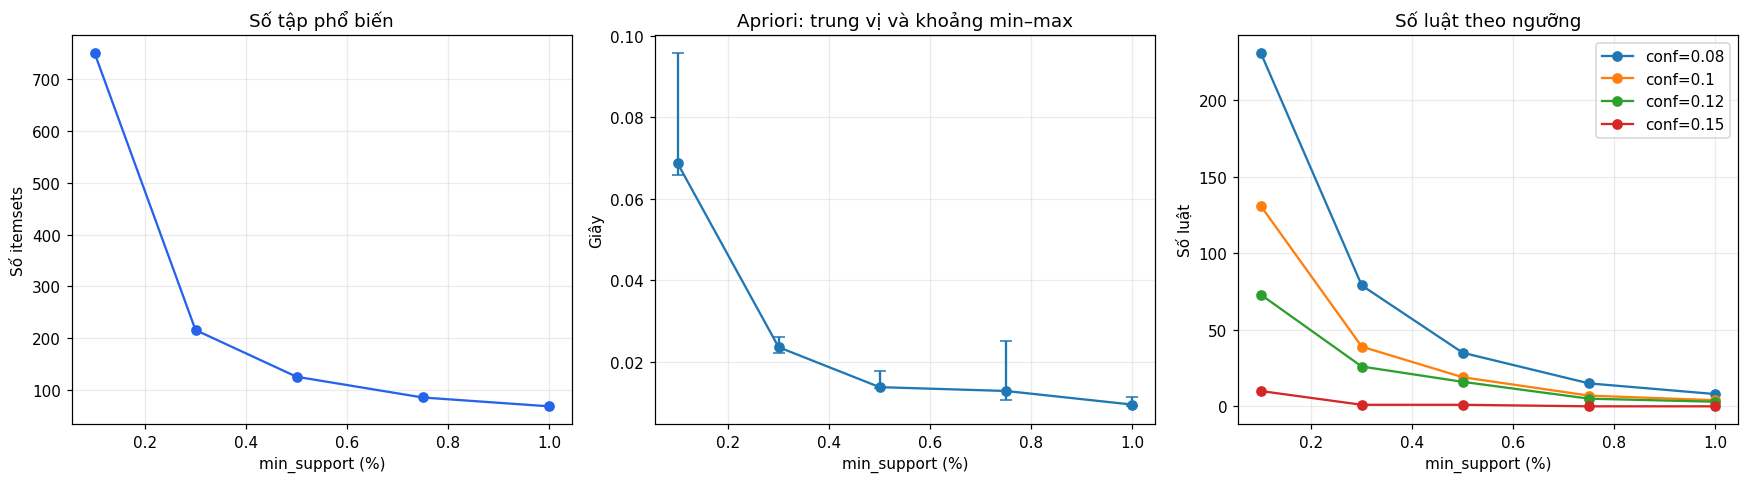

**Nhận xét:** Khi tăng support từ 0.001 lên 0.01, số tập phổ biến thay đổi từ 750 xuống 69. Thời gian Apriori trung vị tương ứng 0.0687s và 0.0094s. Tăng confidence tại một support cố định chỉ có thể giữ nguyên hoặc giảm số luật. Thời gian không bắt buộc biến thiên đơn điệu do nhiễu đo và chi phí xử lý từng lần.

,min_support,size,count
0,0.0010,1,149
1,0.0010,2,592
2,0.0010,3,9
3,0.0030,1,111
4,0.0030,2,105
5,0.0050,1,89
6,0.0050,2,37
7,0.0075,1,74
8,0.0075,2,12
9,0.0100,1,64


In [ ]:
by_support = summary.drop_duplicates('min_support').sort_values('min_support')
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
x = by_support['min_support'] * 100
axes[0].plot(x, by_support['frequent_itemsets'], 'o-', color='#2563eb')
axes[0].set(title='Số tập phổ biến', ylabel='Số itemsets')
axes[1].errorbar(x, by_support['apriori_s_median'],
    yerr=[by_support['apriori_s_median']-by_support['apriori_s_min'],
          by_support['apriori_s_max']-by_support['apriori_s_median']], fmt='o-', capsize=4)
axes[1].set(title='Apriori: trung vị và khoảng min–max', ylabel='Giây')
for confidence in CONFIDENCES:
    part = summary[summary['min_confidence'].eq(confidence)].sort_values('min_support')
    axes[2].plot(part['min_support'] * 100, part['rules'], 'o-', label=f'conf={confidence:g}')
axes[2].set(title='Số luật theo ngưỡng', ylabel='Số luật')
axes[2].legend()
for ax in axes:
    ax.set_xlabel('min_support (%)')
    ax.grid(alpha=.25)
fig.tight_layout()
fig.savefig(OUT / '01_AnhHuongNguong.png', bbox_inches='tight')
plt.show()
lo, hi = by_support.iloc[0], by_support.iloc[-1]
nhan_xet(f'Khi tăng support từ {lo.min_support:g} lên {hi.min_support:g}, '
         f'số tập phổ biến thay đổi từ {int(lo.frequent_itemsets)} xuống {int(hi.frequent_itemsets)}. '
         f'Thời gian Apriori trung vị tương ứng {lo.apriori_s_median:.4f}s và {hi.apriori_s_median:.4f}s. '
         'Tăng confidence tại một support cố định chỉ có thể giữ nguyên hoặc giảm số luật. '
         'Thời gian không bắt buộc biến thiên đơn điệu do nhiễu đo và chi phí xử lý từng lần.')

size_rows = [{'min_support': s, 'size': k, 'count': int(v)}
             for s, f in frequent_by_support.items()
             for k, v in f['itemsets'].map(len).value_counts().sort_index().items()]
size_distribution = pd.DataFrame(size_rows, columns=['min_support', 'size', 'count'])
display(size_distribution)


## 5. Phân tích một cấu hình và Top luật
Mặc định xem `support=0.003, confidence=0.10`; có thể thay bằng một cặp đã chạy. Đây là cấu hình minh họa, **không gọi là tối ưu** khi chưa kiểm tra trên dữ liệu mới hoặc đánh giá nghiệp vụ.

Hiển thị cả Top luật theo confidence và nhóm luật có lift > 1. Với kiểm tra “confidence tương đối cao nhưng lift gần 1”, dùng quy ước rõ ràng: confidence ≥ 0.15 và |lift − 1| ≤ 0.05. Đây chỉ là ngưỡng minh họa cho bài phân tích.


In [ ]:
SELECT_SUPPORT = 0.003
SELECT_CONFIDENCE = 0.10
if (SELECT_SUPPORT, SELECT_CONFIDENCE) not in rules_by_config:
    raise ValueError('Chọn support/confidence trong các ngưỡng đã chạy.')
selected_freq = frequent_by_support[SELECT_SUPPORT]
selected_rules = rules_by_config[(SELECT_SUPPORT, SELECT_CONFIDENCE)]
selected_table = readable_rules(selected_rules)
print('Top tập phổ biến:')
display(readable_itemsets(selected_freq).sort_values('support', ascending=False).head(15))
print('Top luật theo confidence (chưa lọc lift):')
display(selected_table.sort_values(['confidence', 'lift'], ascending=False).head(10).round(6))
positive = selected_table[selected_table['lift'].gt(1)].sort_values(
    ['lift', 'support', 'confidence'], ascending=False)
print('Luật có lift > 1 trong cấu hình đã chọn:')
display(positive.head(10).round(6))
if selected_table.empty:
    nhan_xet('Không có luật thỏa cấu hình này. Đây là kết quả hợp lệ; xem dải ngưỡng thấp hơn, '
             'không tự tạo luật hoặc kết luận thuật toán bị lỗi.')
else:
    row = selected_table.sort_values(['confidence', 'lift'], ascending=False).iloc[0]
    nhan_xet(f'Luật {row.antecedents} → {row.consequents} có support={row.support:.4%}, '
             f'tức {row.cooccurrence_count} trên {N:,} giỏ chứa cả hai vế; '
             f'confidence={row.confidence:.2%}; lift={row.lift:.3f}. '
             f'Có {len(positive)} luật với lift > 1 trong tổng {len(selected_table)} luật. '
             'Nếu lift ≤ 1, confidence đơn lẻ không đủ để chọn làm gợi ý mua kèm.')

# Dùng toàn bộ luật đã khai thác để tìm ví dụ, loại sự lặp giữa các cấu hình.
all_rules = pd.concat([readable_rules(r) for r in rules_by_config.values()], ignore_index=True)
all_rules = all_rules.drop_duplicates(['antecedents', 'consequents']).reset_index(drop=True)
near_independent = all_rules[(all_rules['confidence'] >= 0.15) &
                             ((all_rules['lift'] - 1).abs() <= 0.05)]
print('Confidence ≥ 0.15 và lift trong [0.95, 1.05]:')
display(near_independent.sort_values('confidence', ascending=False).head(10).round(6))
if near_independent.empty:
    nhan_xet('Không tìm thấy luật đáp ứng đồng thời định nghĩa minh họa trên trong lưới đã thử. '
             'Không có ví dụ phù hợp cũng là một kết quả cần báo cáo.')
else:
    nhan_xet('Các luật trên có confidence tương đối cao trong dải đang thử, nhưng lift gần 1. '
             'Xác suất có sản phẩm ở vế phải gần mức phổ biến sẵn có của chính sản phẩm đó.')


Top tập phổ biến:
Top luật theo confidence (chưa lọc lift):
Luật có lift > 1 trong cấu hình đã chọn:
Confidence ≥ 0.15 và lift trong [0.95, 1.05]:


<ipython-input-1-40f1da2d02f9>:28: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  all_rules = pd.concat([readable_rules(r) for r in rules_by_config.values()], ignore_index=True)


,support,itemsets,size,count
108,0.157923,whole milk,1,2363
67,0.122101,other vegetables,1,1827
82,0.110005,rolls/buns,1,1646
91,0.097106,soda,1,1453
109,0.085879,yogurt,1,1285
83,0.069572,root vegetables,1,1041
101,0.067767,tropical fruit,1,1014
7,0.060683,bottled water,1,908
86,0.060349,sausage,1,903
22,0.053131,citrus fruit,1,795


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,cooccurrence_count
2,bottled beer,whole milk,0.045312,0.157923,0.007151,0.157817,0.999330,107
32,sausage,whole milk,0.060349,0.157923,0.008955,0.148394,0.939663,134
21,newspapers,whole milk,0.038896,0.157923,0.005614,0.144330,0.913926,84
12,domestic eggs,whole milk,0.037091,0.157923,0.005280,0.142342,0.901341,79
19,hamburger meat,whole milk,0.021854,0.157923,0.003074,0.140673,0.890769,46
14,frankfurter,whole milk,0.037760,0.157923,0.005280,0.139823,0.885388,79
0,beef,whole milk,0.033950,0.157923,0.004678,0.137795,0.872548,70
13,frankfurter,other vegetables,0.037760,0.122101,0.005146,0.136283,1.116150,77
16,frozen vegetables,whole milk,0.028002,0.157923,0.003809,0.136038,0.861422,57
29,pork,whole milk,0.037091,0.157923,0.005012,0.135135,0.855703,75


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,cooccurrence_count
13,frankfurter,other vegetables,0.037760,0.122101,0.005146,0.136283,1.116150,77
17,fruit/vegetable juice,rolls/buns,0.034017,0.110005,0.003743,0.110020,1.000136,56


**Nhận xét:** Luật bottled beer → whole milk có support=0.7151%, tức 107 trên 14,963 giỏ chứa cả hai vế; confidence=15.78%; lift=0.999. Có 2 luật với lift > 1 trong tổng 39 luật. Nếu lift ≤ 1, confidence đơn lẻ không đủ để chọn làm gợi ý mua kèm.

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,cooccurrence_count
62,detergent,whole milk,0.008621,0.157923,0.001403,0.162791,1.030824,21
89,ham,whole milk,0.017109,0.157923,0.002740,0.160156,1.014142,41
13,bottled beer,whole milk,0.045312,0.157923,0.007151,0.157817,0.999330,107
73,frozen fish,whole milk,0.006817,0.157923,0.001069,0.156863,0.993287,16


**Nhận xét:** Các luật trên có confidence tương đối cao trong dải đang thử, nhưng lift gần 1. Xác suất có sản phẩm ở vế phải gần mức phổ biến sẵn có của chính sản phẩm đó.

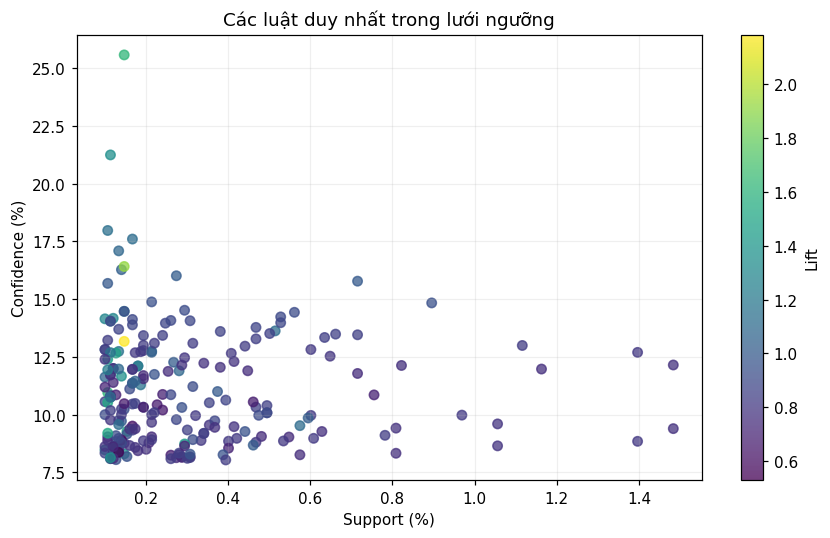

In [ ]:
if not all_rules.empty:
    fig, ax = plt.subplots(figsize=(8, 5))
    points = ax.scatter(all_rules['support']*100, all_rules['confidence']*100,
                        c=all_rules['lift'], cmap='viridis', s=38, alpha=.75)
    fig.colorbar(points, ax=ax, label='Lift')
    ax.set(xlabel='Support (%)', ylabel='Confidence (%)',
           title='Các luật duy nhất trong lưới ngưỡng')
    ax.grid(alpha=.2)
    fig.tight_layout()
    fig.savefig(OUT / '02_SupportConfidenceLift.png', bbox_inches='tight')
    plt.show()
else:
    print('Không có luật để vẽ biểu đồ support–confidence.')
